# Laboratorio 10. Clasificación con Keras

Redes para lunas y dígitos con ReLU en las capas ocultas. Uso salida sigmoide para dos clases y softmax para diez.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.datasets import make_moons, load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

keras.utils.set_random_seed(42)

# Usamos la misma separación en ambos problemas: 60 % ajuste, 20 % validación y 20 % prueba.
def separar(X, y):
    X_des, X_test, y_des, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)
    X_train, X_val, y_train, y_val = train_test_split(X_des, y_des, test_size=.25,
                                                    stratify=y_des, random_state=42)
    return X_train, X_val, X_test, y_train, y_val, y_test

def curvas(historia):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, metrica in zip(axes, ['loss', 'accuracy']):
        ax.plot(historia.history[metrica], label='Entrenamiento')
        ax.plot(historia.history['val_' + metrica], label='Validación')
        ax.set(xlabel='Época', ylabel=metrica)
        ax.legend()
    plt.tight_layout()
    plt.show()

## 1. Dos lunas

Uso dos capas ocultas para separar la frontera curva. Ajusto el escalado con entrenamiento y elijo la época con validación.

Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 337 (1.32 KB)
 Trainable params: 337 (1.32 KB)
 Non-trainable params: 0 (0.00 B)
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       100
           1       0.98      1.00      0.99       100

    accuracy               

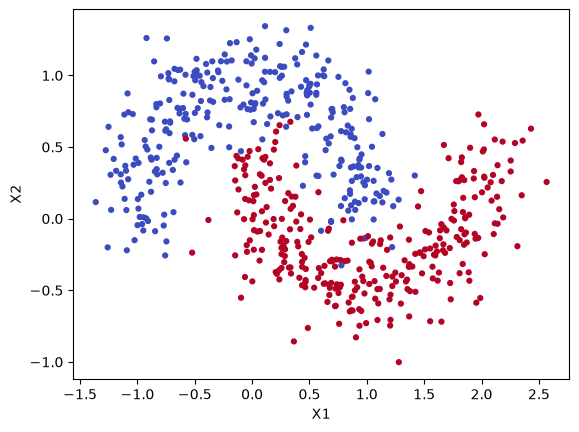

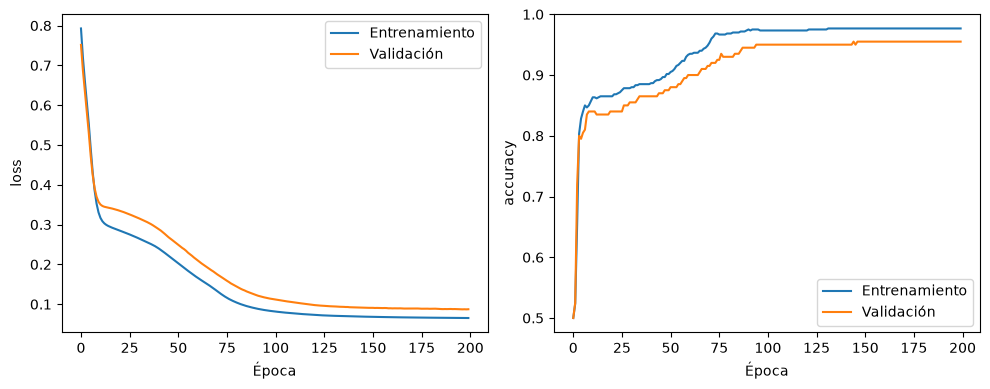

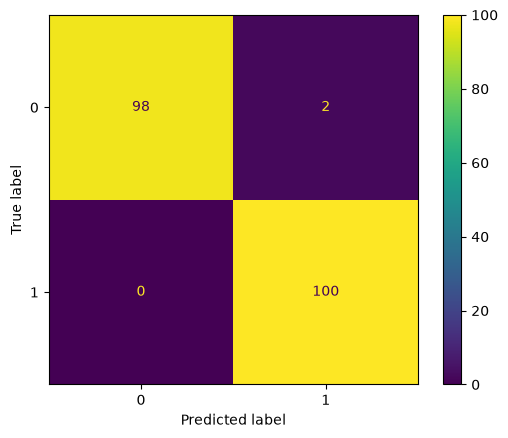

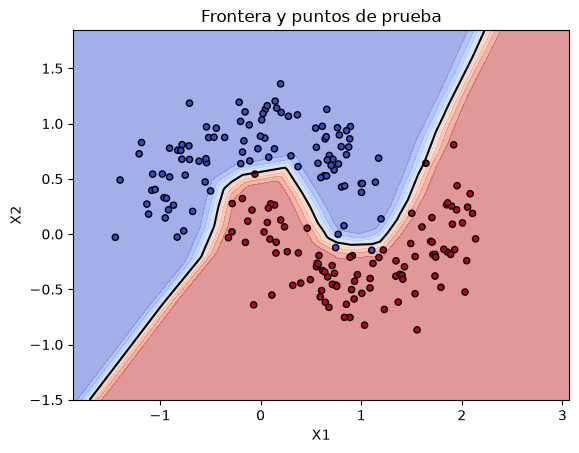

In [2]:
X, y = make_moons(n_samples=1000, noise=.2, random_state=42)
Xtr, Xv, Xte, ytr, yv, yte = separar(X, y)
scaler = StandardScaler().fit(Xtr)
Xtr_s, Xv_s, Xte_s = [scaler.transform(z) for z in [Xtr, Xv, Xte]]
plt.scatter(Xtr[:, 0], Xtr[:, 1], c=ytr, cmap='coolwarm', s=12)
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()

# La única neurona de salida estima la probabilidad de la clase 1.
modelo_lunas = keras.Sequential([keras.Input(shape=(2,)),
    keras.layers.Dense(16, activation='relu'), keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')])
modelo_lunas.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
modelo_lunas.summary()
historia = modelo_lunas.fit(Xtr_s, ytr, validation_data=(Xv_s, yv), epochs=200,
    batch_size=32, verbose=0, callbacks=[keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=20, restore_best_weights=True)])
curvas(historia)

# La evaluación se hace después de fijar el modelo con validación.
pred = (modelo_lunas.predict(Xte_s, verbose=0).ravel() >= .5).astype(int)
print(classification_report(yte, pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(yte, pred)
plt.show()
xx, yy = np.meshgrid(np.linspace(Xtr[:, 0].min()-.5, Xtr[:, 0].max()+.5, 200),
                     np.linspace(Xtr[:, 1].min()-.5, Xtr[:, 1].max()+.5, 200))
prob = modelo_lunas.predict(scaler.transform(np.c_[xx.ravel(), yy.ravel()]), verbose=0).reshape(xx.shape)
plt.contourf(xx, yy, prob, levels=np.linspace(0, 1, 11), cmap='coolwarm', alpha=.5)
plt.contour(xx, yy, prob, levels=[.5], colors='black')
plt.scatter(Xte[:, 0], Xte[:, 1], c=yte, cmap='coolwarm', edgecolor='black', s=20)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Frontera y puntos de prueba')
plt.show()

## 2. Dígitos

Uso las diez clases de dígitos. Las imágenes de 8×8 píxeles dan 64 entradas; divido por 16, el máximo conocido de intensidad.

Model: "sequential_1"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 6,570 (25.66 KB)
 Trainable params: 6,570 (25.66 KB)
 Non-trainable params: 0 (0.00 B)
              precision    recall  f1-score   support

           0       1.00      0.94      0.97        36
           1       0.88      0.83      0.86        36
           2       0

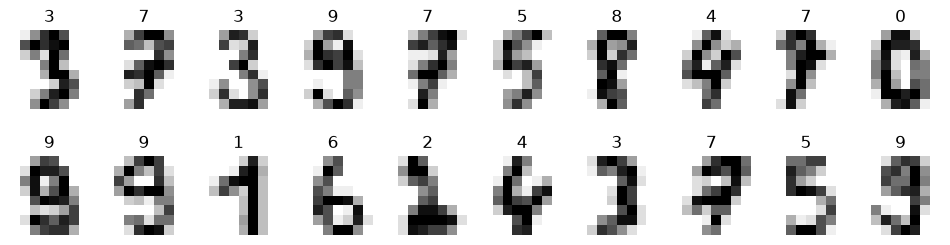

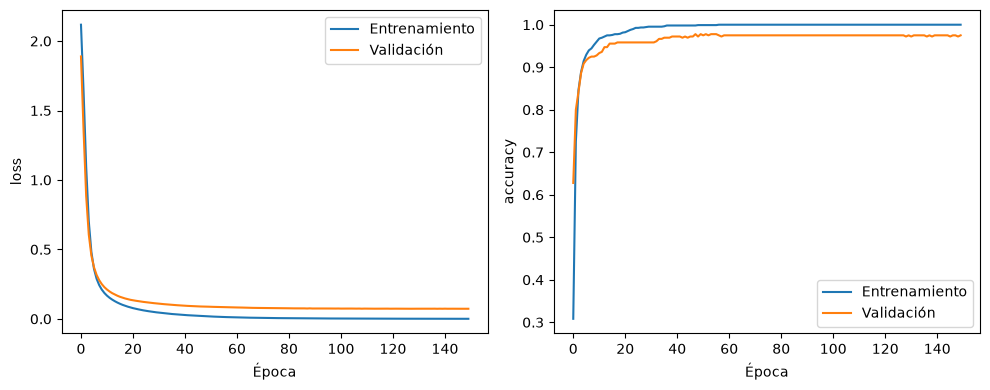

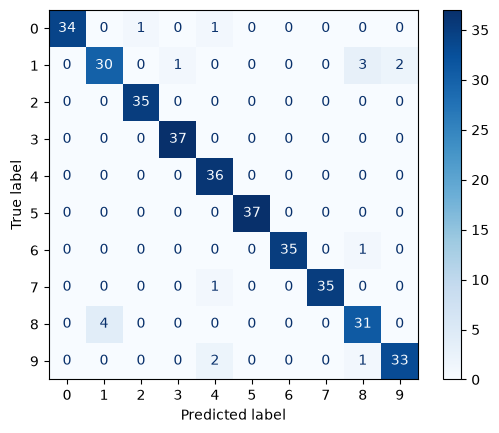

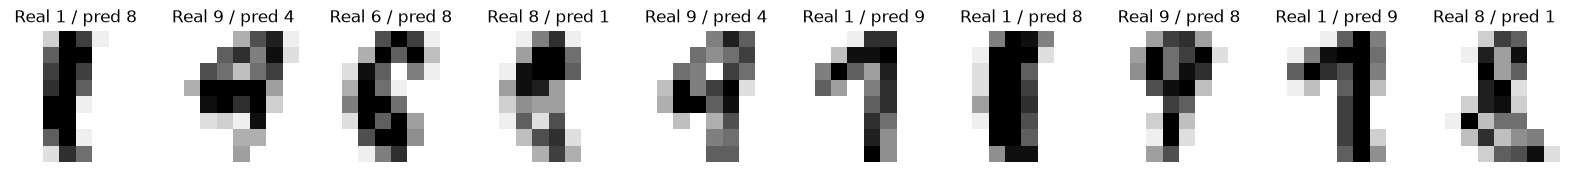

In [3]:
digitos = load_digits()
Xtr, Xv, Xte, ytr, yv, yte = separar(digitos.data / 16., digitos.target)
fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for ax, imagen, etiqueta in zip(axes.ravel(), Xtr[:20], ytr[:20]):
    ax.imshow(imagen.reshape(8, 8), cmap='binary')
    ax.set_title(str(etiqueta))
    ax.axis('off')
plt.show()

# Softmax devuelve diez probabilidades que suman uno.
modelo_digitos = keras.Sequential([keras.Input(shape=(64,)),
    keras.layers.Dense(64, activation='relu'), keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(10, activation='softmax')])
modelo_digitos.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
modelo_digitos.summary()
historia_digitos = modelo_digitos.fit(Xtr, ytr, validation_data=(Xv, yv), epochs=150,
    batch_size=32, verbose=0, callbacks=[keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=15, restore_best_weights=True)])
curvas(historia_digitos)
probabilidades = modelo_digitos.predict(Xte, verbose=0)
pred = probabilidades.argmax(axis=1)
assert np.allclose(probabilidades.sum(axis=1), 1, atol=1e-5)
print(classification_report(yte, pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues')
plt.show()

# Mostramos errores reales de esta ejecución, si los hay.
errores = np.flatnonzero(pred != yte)[:10]
if len(errores):
    fig, axes = plt.subplots(1, len(errores), figsize=(2*len(errores), 3), squeeze=False)
    for ax, i in zip(axes.ravel(), errores):
        ax.imshow(Xte[i].reshape(8, 8), cmap='binary')
        ax.set_title(f'Real {yte[i]} / pred {pred[i]}')
        ax.axis('off')
    plt.show()
print('Accuracy en dígitos:', np.mean(pred == yte))

Las curvas comparan entrenamiento y validación; la matriz muestra qué clases se confunden. Los resultados corresponden a estas particiones e imágenes de 8×8.